# Visión por Computador - Práctica 3 - Deep Learning en Computer Vision

#### 20 puntos   |   Fecha de entrega: 20 de diciembre de 2026, 23:59   |   Forma de entrega: a través de la tarea creada en https://pradogrado2627.ugr.es/

### Estudiante: <mark>POR FAVOR, INTRODUZCA AQUÍ SU NOMBRE COMPLETO</mark>



## Normas de desarrollo y entrega de la práctica

1. Para este trabajo, al igual que para los demás, se debe presentar código, resultados, discusión de los mismos, y presentación y análisis del trabajo realizado, todo integrado en el propio Google Colab Notebook (es decir, no se entrega ninguna memoria separada en `.pdf` ni ningún código `.py`). Se recuerda que código y resultados sin informe explicativo no puntúa. Resulta también fundamental recordar que solo se acepta la entrega de ficheros `.ipynb` (no resulta válido entregar un fichero `.py`).

2. En relación con el punto anterior, se recuerda que se proporciona un Notebook, denominado `Ejemplo_Otsu.ipynb`, que muestra un ejemplo de respuesta y solución a un potencial ejercicio. El propósito de este Notebook es servir de referencia al alumnado acerca de cómo responder los ejercicios planteados. Véase que, por ejemplo, en aras de diferenciar con facilidad enunciados y respuestas, estas últimas se presentan en otro color (azul, en ese caso).

3. El diseño de celdas del documento debe ser respetado. Es decir, no se puede modificar el orden de los ejercicios o alterar la estructura del Notebook, de forma que dificulte localizar los contenidos. Aunque sí se puede, por ejemplo, crear nuevas subsecciones dentro de las secciones ya existentes para estructurar y organizar con más claridad las respuestas, así como para incluir los experimentos extra que se deseen.

4. Tal y como se muestra en `Ejemplo_Otsu.ipynb`, no hay ningún problema en emplear técnicas de IA generativa (como ChatGPT o Gemini) para crear el código de los distintos ejercicios o para enriquecer el análisis y descripción del trabajo realizado (aunque, obvia decirlo, su uso no es obligatorio). Pero, en caso de usarse, sí se debe aclarar de qué modo se ha usado la IA, con qué objetivo, y se debe demostrar que se entiende perfectamente lo que se ha hecho.

5. Solo se entregará el fichero `.ipynb` (incorporando código, resultados, y explicación del trabajo realizado y los resultados obtenidos) y no se enviarán las imágenes empleadas. El path para la lectura de imágenes, o cualquier otro fichero de entrada, debe ser siempre “/content/drive/My Drive/images/nombre_fichero” (salvo que se indique lo contrario explícitamente en un ejercicio concreto; por ejemplo, si un ejercicio determina una ubicación propia para un determinado conjunto de datos).

6. El código deberá  presentarse adecuadamente comentado y con los resultados obtenidos en cada apartado, junto con la presentación del trabajo realizado y la discusión y análisis de los resultados obtenidos. Es importante reiterar que la entrega de código sin informe explicativo o valoraciones no puntúa. Por otro lado, el código debe ir comentado en comentarios en celdas de código, mientras que el análisis y discusión, tanto del trabajo realizado como de los resultados obtenidos, debe ir en celdas de texto.

Este trabajo de implementación tiene como objetivo principal **familiarizarse con la implementación y diseño de redes convolucionales para problemas de visión por computador**.




### Materiales de Apoyo

En caso de que el alumnado tenga dudas sobre Python, OpenCV o el uso de Google Colab, se recuerda que en PRADO hay materiales de apoyo (https://pradogrado2627.ugr.es/mod/folder/view.php?id=83733):
-  Introducción a Python: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/1.%20Introduccion%20a%20Python.pdf
- Introducción a NumPy, Matplotlib y Scikit-learn: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/2.%20Introducci%C3%B3n%20a%20Numpy%20Matplotlib%20y%20sklearn.pdf
- Notebook con toda la información anterior (y más cosas): https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Guia_Python.ipynb
- Ejercicios y ejemplos de repaso: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/3.%20Ejercicios%20y%20ejemplos%20de%20repaso.pdf
- Fundamentos de Python para lectura, visualización y manipulación de imágenes: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/4.%20Fundamentos%20de%20Python%20para%20manipulacion%20de%20imagenes.pdf(y Notebook asociado: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Guia_fundamentos_imagenes.ipynb)
- Ideas sobre cómo redactar un documento académico-científico (útil para saber cómo documentar las respuestas a los ejercicios, el Notebook en su conjunto, y la memoria del proyecto final o de un TFG/TFM): https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Algunas%20ideas%20sobre%20c%C3%B3mo%20elaborar%20un%20informe%20acad%C3%A9mico-cient%C3%ADfico.pdf
- Ejemplo de respuesta a un hipotético ejercicio sobre el algoritmo de umbralización de Otsu: https://pradogrado2627.ugr.es/pluginfile.php/153448/mod_folder/content/0/Ejemplo_Otsu.ipynb

<font color='blue'>El objetivo de esta práctica es aprender a diseñar, implementar, entrenar y utilizar (es decir, aplicar en inferencia) redes neuronales convolucionales en tareas de visión por computador (clasificación y regresión en imágenes, IA explicable y segmentación de imágenes) usando fastai (https://docs.fast.ai/).

<font color='blue'>Se proporciona una guía de ayuda (`P3_HG.ipynb`) para, entre otras cosas, saber cómo:
1. realizar funciones básicas de lectura de datos, entrenamiento y optimización;
2. crear gráficos para la evolución del error de clasificación en
los conjuntos de entrenamiento y validación;
3. y calcular el error de clasificación en el conjunto de prueba.

In [ ]:
# The first thing we should do is to apply hardware acceleration via GPU. So, we have to go to Editar - Configuracion del Cuaderno - Acelerador por Hardware GPU

# Now we SET UP Fastai
!pip install -Uqq fastbook
!pip install nbdev
import fastbook
fastbook.setup_book()
import fastai
import fastcore
print(f'fastcore version {fastcore.__version__} installed')
print(f'fastai version {fastai.__version__} installed')
from nbdev.showdoc import *
from fastai.vision.all import *

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [nbdev]
Mounted at /content/gdrive
fastcore version 2.2.35 installed
fastai version 2.8.12 installed



### <font color='blue'>**Funciones auxiliares para visualizar el entrenamiento**

<font color='blue'>A continuación, definimos dos utilidades que complementan las herramientas de visualización de fastai. Ambas permiten analizar la evolución del entrenamiento, pero tienen objetivos diferentes.

<font color='blue'>**1. `plot_metrics()`: visualización de las métricas después del entrenamiento**

<font color='blue'>Esta función personalizada, adaptada a partir de una implementación de Ignacio Oguiza, permite representar gráficamente la evolución de las métricas registradas por fastai a lo largo de las épocas. La incorporamos a la clase `Recorder` mediante el decorador `@patch`, de manera que podemos invocarla directamente como un método de `learn.recorder`. Su principal utilidad es facilitar la comparación entre las métricas calculadas sobre entrenamiento y validación, como *accuracy*, *F1-score*, MAE o MSE, según el problema abordado. La versión adaptada identifica las métricas por su nombre y agrupa las correspondientes a entrenamiento y validación cuando ambas están disponibles. Además, permite generar automáticamente varias gráficas.

<font color='blue'>Ejemplo de uso (después del entrenamiento):

```python
learn.recorder.plot_metrics()
```

<font color='blue'>Para registrar también las métricas sobre el conjunto de entrenamiento, además de las de validación, podemos activar la siguiente opción  antes de entrenar:

```python
learn.recorder.train_metrics = True
```

<font color='blue'>Esto permite comparar directamente la evolución de ambas métricas y estudiar posibles indicios de sobreajuste. La función no calcula nuevas métricas: representa los valores previamente almacenados por `Recorder`.

<font color='blue'>**2. `FixedShowGraphCallback`: visualización de las pérdidas durante el entrenamiento**

<font color='blue'>Esta clase es una adaptación de `ShowGraphCallback` de fastai, utilizada para visualizar dinámicamente las pérdidas mientras se entrena el modelo. En determinadas versiones de fastai, el callback original puede representar incorrectamente las curvas cuando se activa `train_metrics=True`, porque presupone que la pérdida de validación ocupa una posición fija dentro del registro de métricas. Nuestra implementación corrige este problema identificando `valid_loss` por su nombre, en lugar de asumir una posición determinada. De esta manera, podemos visualizar correctamente:
- <font color='blue'>La pérdida de entrenamiento, registrada a lo largo de los minibatches.
- La pérdida de validación, calculada al finalizar cada época.

**Ejemplo de uso:**

```python
learn.recorder.train_metrics = True

cbs = [FixedShowGraphCallback()]
learn.fit(15, cbs=cbs)
```

<font color='blue'>A diferencia de `plot_metrics()`, esta clase debe incorporarse como callback durante el entrenamiento. No se invoca posteriormente para visualizar las métricas.

<font color='blue'>**En resumen:** `FixedShowGraphCallback` permite seguir las pérdidas **durante el entrenamiento**, mientras que `plot_metrics()` permite analizar las métricas **después del entrenamiento**.


In [ ]:
# Visualiza la evolución de las métricas registradas durante el entrenamiento.
# Permite comparar las métricas de entrenamiento y validación cuando ambas
# están disponibles, agrupándolas por nombre.
# Se incorpora a Recorder mediante @patch.
# Uso (después de entrenar): learn.recorder.plot_metrics()
# Adaptada a partir de la implementación de Ignacio Oguiza (https://forums.fast.ai/t/plotting-metrics-after-learning/69937).
@patch
@delegates(subplots)
def plot_metrics(self: Recorder, nrows=None, ncols=None, figsize=None, **kwargs):
    metrics = np.asarray(self.values, dtype=float)
    names = [name for name in self.metric_names[1:] if name != 'time']

    if metrics.ndim != 2 or metrics.shape[1] != len(names):
        raise ValueError("Metric names do not match recorded values.")

    # Group training and validation metrics by name
    grouped = {}
    for i, name in enumerate(names):
        if name.startswith('train_'):
            split, base = 'train', name[len('train_'):]
        elif name.startswith('valid_'):
            split, base = 'valid', name[len('valid_'):]
        else:
            split, base = 'valid', name

        grouped.setdefault(base, {})[split] = i

    n = len(grouped)

    if nrows is None and ncols is None:
        nrows = max(1, int(math.sqrt(n)))
        ncols = int(np.ceil(n / nrows))
    elif nrows is None:
        nrows = int(np.ceil(n / ncols))
    elif ncols is None:
        ncols = int(np.ceil(n / nrows))

    figsize = figsize or (ncols * 6, nrows * 4)
    fig, axs = subplots(nrows, ncols, figsize=figsize, **kwargs)
    axs = np.asarray(axs).reshape(-1)

    epochs = np.arange(len(metrics))

    for ax, (name, cols) in zip(axs, grouped.items()):
        for split, color in [('train', '#1f77b4'), ('valid', '#ff7f0e')]:
            if split in cols:
                ax.plot(epochs, metrics[:, cols[split]],
                        color=color, label=split)

        ax.set_title(name)
        ax.set_xlabel('Epoch')
        ax.legend(loc='best')

    for ax in axs[n:]:
        ax.set_axis_off()

    fig.tight_layout()
    plt.show()


# Versión adaptada de ShowGraphCallback para visualizar las pérdidas
# durante el entrenamiento, compatible con train_metrics=True/False.
# Identifica 'valid_loss' por su nombre para evitar seleccionar
# una métrica incorrecta cuando cambia el orden de los registros.
# Uso: learn.fit(15, cbs=[FixedShowGraphCallback()])
class FixedShowGraphCallback(ShowGraphCallback):

    def after_epoch(self):
        if not self.nb_batches:
            return

        rec = self.learn.recorder

        # Identify the validation loss by name
        names = rec.metric_names[1:-1]
        valid_idx = names.index('valid_loss')

        train_losses = [float(v) for v in rec.losses]
        valid_losses = [
            float(v[valid_idx]) for v in rec.values
        ]

        iters = range(len(train_losses))

        x_bounds = (
            0,
            (self.n_epoch - len(self.nb_batches)) *
            self.nb_batches[0] + len(train_losses)
        )

        y_bounds = (
            0,
            max(max(train_losses), max(valid_losses))
        )

        self.progress.mbar.update_graph(
            [
                (iters, train_losses),
                (self.nb_batches, valid_losses)
            ],
            x_bounds,
            y_bounds
        )






---



---



---



# <font color='blue'>**Ejercicio 1: BaseNet en CIFAR100 (5 puntos)**





## <font color='blue'> Creación, entrenamiento y validación del modelo (4 puntos)

<font color='blue'>**Dataset:**
En este ejercicio, trabajaremos con parte del conjunto de datos $\textit{CIFAR100}$ (https://www.cs.toronto.edu/~kriz/cifar.html). Este clásico conjunto de datos consta de $60000$ imágenes en color de $32\times32\times3$ (RGB) que representan $100$ clases diferentes ($600$ imágenes por clase). Hay $50000$ imágenes para entrenamiento y $10000$ para test. Los alumnos deben emplear el $20\%$ del conjunto de entrenamiento para  validación.

<font color='blue'>**Modelo BaseNet:**
La arquitectura exacta a implementar se define en la siguiente tabla:

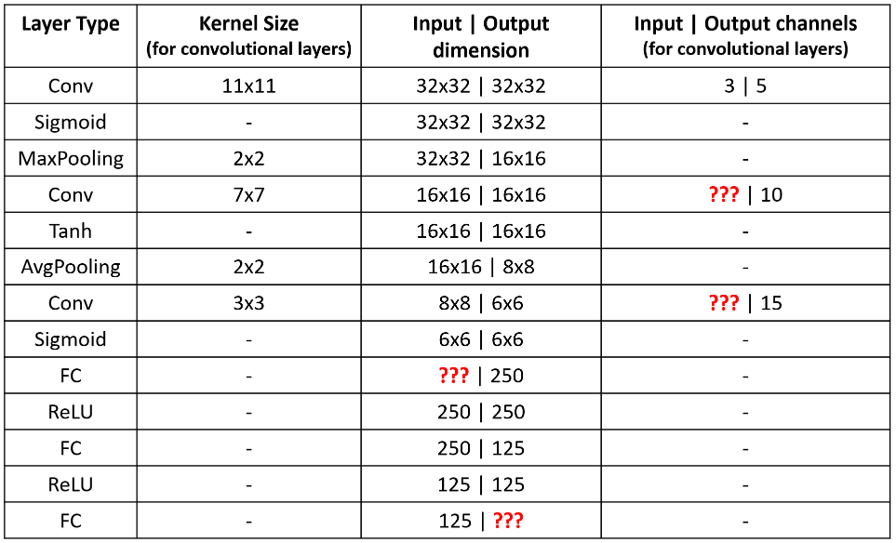

<font color='blue'>Nótese que hay varios elementos en la arquitectura que se marcan en rojo con interrogantes. Esto se debe a que es el alumnado el que debe calcular los valores correspondientes y explicar el cálculo realizado.

<font color='blue'>Los alumnos deben:
1. Crear el código para el modelo *BaseNet* empleando fastai/PyTorch.
2. Explicar y describir cada una de las capas de la arquitectura *BaseNet*, así como las decisiones de implementación tomadas. Por ejemplo:
    - <font color='blue'>¿Qué función de pérdida se debería emplear: `CrossEntropyLoss()`, `CrossEntropyLossFlat()` o alguna otra?
    - ¿Se debería incorporar manualmente, en la definición de la red, la función de activación de la capa final (`nn.Softmax()`)? ¿Por qué?
    - ¿Cómo se ha calculado la dimensionalidad de los distintos elementos marcados en rojo y con interrogantes en la tabla?
3. Desglosar detalladamente el número de parámetros de esta arquitectura, y cuánto contribuye cada capa a dicho número total. Se debe hacer un `summary()` del modelo para verificar que la arquitectura se ha construido adecuadamente y que el número de parámetros es correcto (es decir, se corresponde con lo calculado previamente). Y, junto con lo anterior, se debe indicar qué porcentaje de todos los parámetros de la red corresponden a las capas _Fully Connected_.
4. Entrenar el modelo, sin aplicar la política de 1 ciclo de Leslie N. Smith, con _SGD_ (`lr=0.1`, `momentum=0.1`), e incluyendo _early stopping_ monitorizando la _loss_ en validación con una paciencia de $5$ durante $15$ épocas, y *batch size* de $64$ ejemplos. Es necesario normalizar los batches utilizando las métricas de ImageNet. A continuación, se debe evaluar el rendimiento por medio de emplear/mostrar/analizar:
    - <font color='blue'>la matriz de confusión en entrenamiento, validación y test;
    - la _accuracy_ en entrenamiento, validación y test;
    - y la evolución de la _loss_, _accuracy_, _Top-5 Accuracy_ y _F1 score (Weighted)_, tanto en entrenamiento como en validación.



In [ ]:
# We get the CIFAR100 dataset
path = untar_data(URLs.CIFAR_100,force_download=True)

<div><progress max="169168619" value="169172992"></progress> 100.00% [169172992/169168619 00:04&lt;00:00]</div>

In [ ]:
# The CIFAR_100 dataset, as well as the MNIST dataset, follows a common layout for machine learning datasets:
# separate folders for the training set and the validation set (and/or test set).
# Let's see what's inside both the training and test sets
print(path)
print(path.ls())
print((path/'train').ls())
print((path/'test').ls())
# train_classes = (path/'train').ls()
# test_classes = (path/'test').ls()
train_classes = sorted((path/'train').ls(), key=lambda p: p.name.casefold())
test_classes  = sorted((path/'test').ls(),  key=lambda p: p.name.casefold())
print([p.name for p in train_classes])  # <-- sorted names
print([p.name for p in test_classes])   # <-- sorted names
print(len(train_classes))

/root/.fastai/data/cifar100
[Path('/root/.fastai/data/cifar100/test'), Path('/root/.fastai/data/cifar100/train')]
[Path('/root/.fastai/data/cifar100/train/food_containers'), Path('/root/.fastai/data/cifar100/train/large_man-made_outdoor_things'), Path('/root/.fastai/data/cifar100/train/insects'), Path('/root/.fastai/data/cifar100/train/vehicles_1'), Path('/root/.fastai/data/cifar100/train/vehicles_2'), Path('/root/.fastai/data/cifar100/train/trees'), Path('/root/.fastai/data/cifar100/train/large_natural_outdoor_scenes'), Path('/root/.fastai/data/cifar100/train/medium_mammals'), Path('/root/.fastai/data/cifar100/train/household_electrical_devices'), Path('/root/.fastai/data/cifar100/train/small_mammals'), Path('/root/.fastai/data/cifar100/train/fish'), Path('/root/.fastai/data/cifar100/train/flowers'), Path('/root/.fastai/data/cifar100/train/fruit_and_vegetables'), Path('/root/.fastai/data/cifar100/train/people'), Path('/root/.fastai/data/cifar100/train/large_carnivores'), Path('/root/.

<font color='blue'>Vemos que hay 20 clases, pero eso no debe confundirnos. Eso son solo las 20 superclases en que está subdividido el dataset. Véase https://github.com/fastai/dlcert2/blob/master/docs/datasets.md:
*"This dataset is just like the CIFAR-10, except it has 100 classes containing 600 images each. There are 500 training images and 100 testing images per class. **The 100 classes in the CIFAR-100 are grouped into 20 superclasses**. Each image comes with a "fine" label (the class to which it belongs) and a "coarse" label (the superclass to which it belongs)."*

In [ ]:
# Queremos verificar que dentro de cada una de las 20 superclases hay 5 clases,
# lo que da las 100 clases que hay. También queremos verificar que el número de imágenes
# es correcto
print('Clases dentro de la primera superclase (',train_classes[0],'): ', train_classes[0].ls())
for i in range(20):
  print('Número de clases dentro de superclase ',i,': ', len(train_classes[i].ls()))
files_train = get_image_files(path/'train')
files_test = get_image_files(path/'test')
print('Total training images: ', len(files_train))
print('Total test images: ', len(files_test))

Clases dentro de la primera superclase ( /root/.fastai/data/cifar100/train/aquatic_mammals ):  [Path('/root/.fastai/data/cifar100/train/aquatic_mammals/beaver'), Path('/root/.fastai/data/cifar100/train/aquatic_mammals/whale'), Path('/root/.fastai/data/cifar100/train/aquatic_mammals/otter'), Path('/root/.fastai/data/cifar100/train/aquatic_mammals/dolphin'), Path('/root/.fastai/data/cifar100/train/aquatic_mammals/seal')]
Número de clases dentro de superclase  0 :  5
Número de clases dentro de superclase  1 :  5
Número de clases dentro de superclase  2 :  5
Número de clases dentro de superclase  3 :  5
Número de clases dentro de superclase  4 :  5
Número de clases dentro de superclase  5 :  5
Número de clases dentro de superclase  6 :  5
Número de clases dentro de superclase  7 :  5
Número de clases dentro de superclase  8 :  5
Número de clases dentro de superclase  9 :  5
Número de clases dentro de superclase  10 :  5
Número de clases dentro de superclase  11 :  5
Número de clases dentro

Numero de ejemplos de entrenamiento (una vez descartados los de validacion): 40000
Numero de ejemplos de validacion: 10000


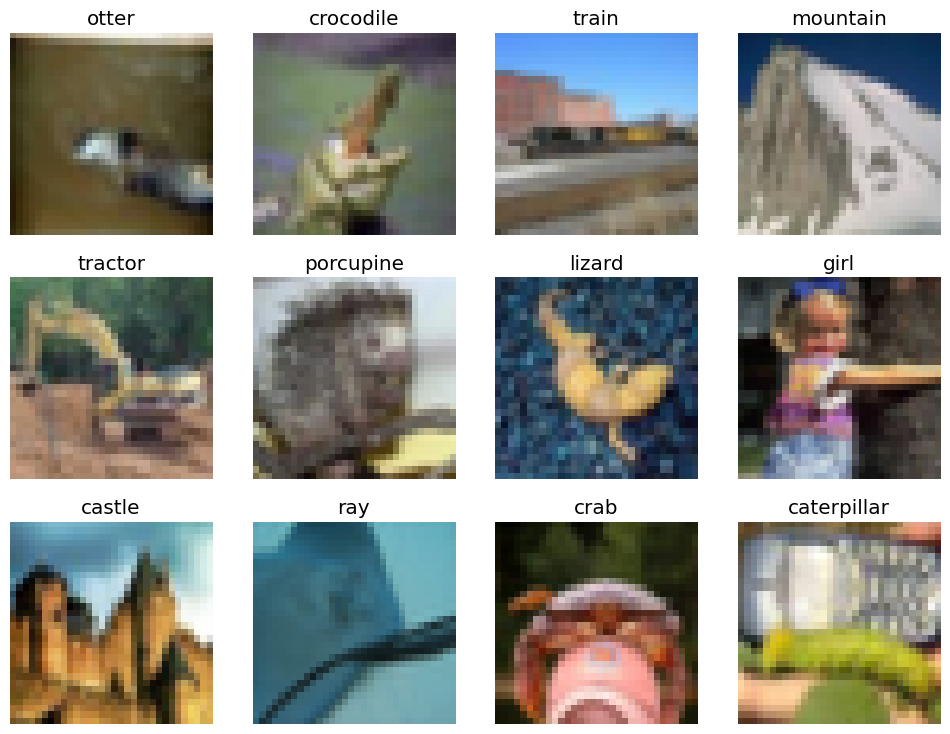

In [ ]:
CIFAR_100 = DataBlock(
    # A CUBRIR POR EL ALUMNADO
)

dls = CIFAR_100.dataloaders(# A CUBRIR POR EL ALUMNADO)


dls.show_batch(max_n=12)

print('Numero de ejemplos de entrenamiento (una vez descartados los de validacion):', len(dls.train_ds))
print('Numero de ejemplos de validacion:', len(dls.valid_ds))

Example of training data


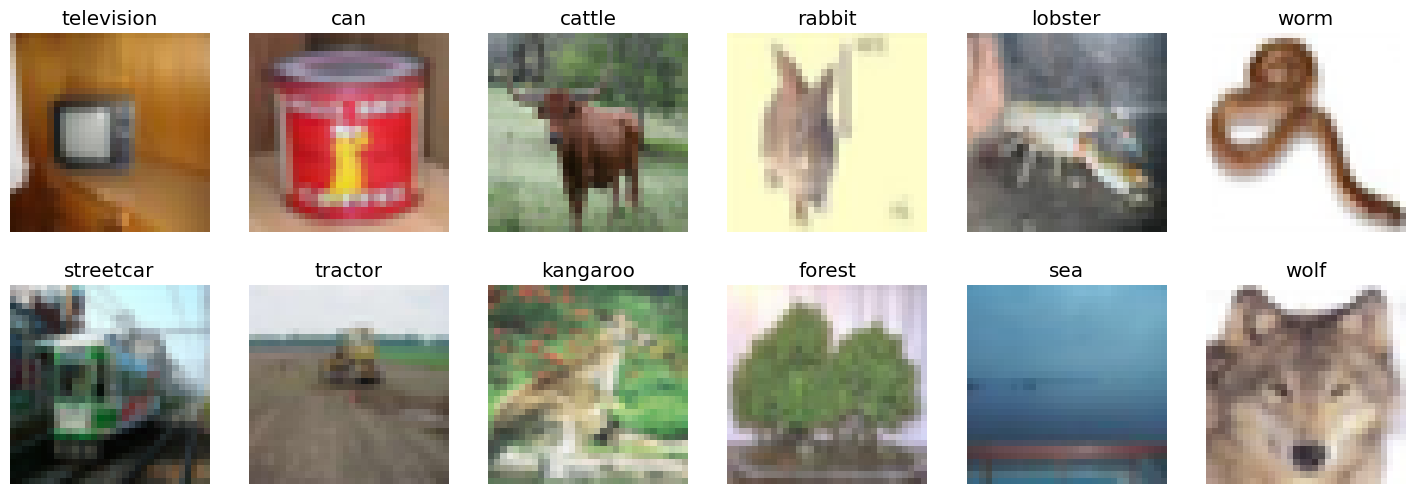

In [ ]:
print('Example of training data')
dls.train.show_batch(max_n=12, nrows=2)

Example of validation data


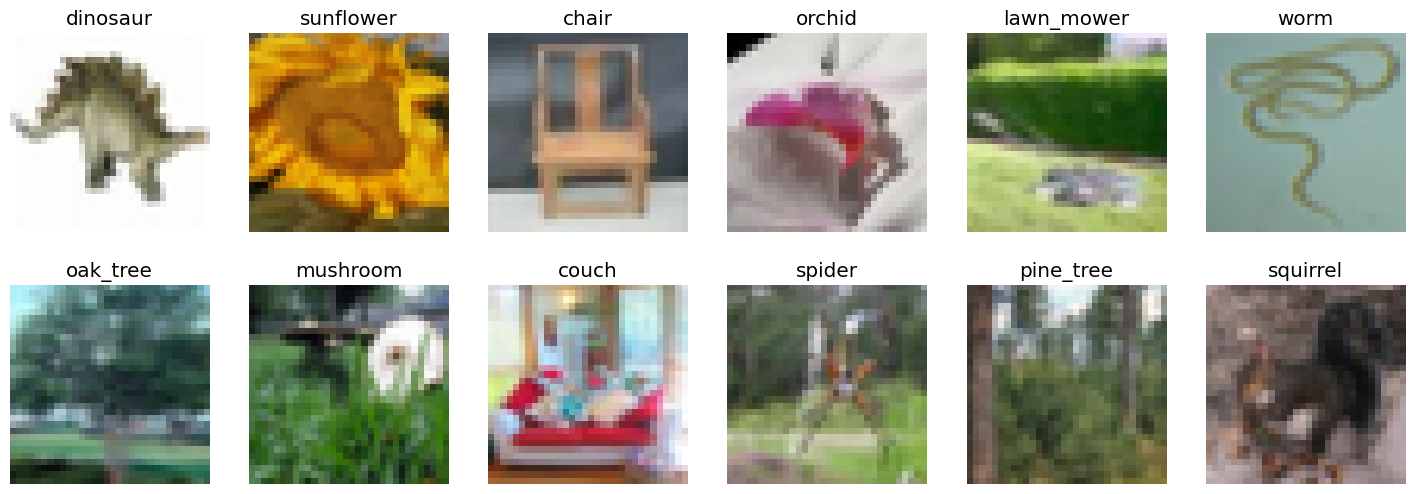

In [ ]:
print('Example of validation data')
dls.valid.show_batch(max_n=12, nrows=2)

In [ ]:

from torch import nn

BaseNet = nn.Sequential(
    # A CUBRIR POR EL ALUMNADO
)

BaseNet


In [ ]:
learn = Learner(# A CUBRIR POR EL ALUMNADO)


In [ ]:
learn.summary()


In [ ]:
# A CUBRIR POR EL ALUMNADO
learn.fit(# A CUBRIR POR EL ALUMNADO)

In [ ]:
# A CUBRIR POR EL ALUMNADO

## <font color='blue'> Comparando GPU y CPU (0.5 puntos)

<font color='blue'>Ahora el alumnado debe entrenar el mismo modelo, pero con CPU (`Entorno de Ejecución - Cambiar tipo de entorno de ejecución - CPU`). ¿Qué ocurre? ¿Hay alguna diferencia en cuanto al entrenamiento? ¿Qué ocurre si empleamos un batch size de tamaño $1$ o $256$ en CPU o GPU?

<font color='blue'>**Nota**: no se trata de realizar un estudio exhaustivo ni de repetir el ejercicio al completo con distintos entornos de ejecución (CPU, GPU A100, GPU L4, GPU G4, GPU T4, TPU v6e-1, TPU v5e-1), aunque, quien quiera, es libre de hacerlo (y, sin duda, se valorará positivamente). Se trata, principalmente, de documentar algunos experimentos (por ejemplo, empleando menos épocas), e intentar explicar los resultados obtenidos a nivel de tiempos de entrenamiento, y cómo en dichos tiempos influye el tamaño del batch y el entorno hardware en que se entrena.

In [ ]:
# A CUBRIR POR EL ALUMNADO

## <font color='blue'> Eliminando FC layers (0.5 puntos)

<font color='blue'>Sabemos que el hecho de tener FC layers en una red convolucional fuerza a la entrada a tener un determinado tamaño. Del mismo modo, sabemos que las FC layers concentran buena parte de los pesos de una red. ¿De qué modo podríamos eliminarlas y construir una arquitectura completamente convolucional?  En este apartado se debe implementar BaseNet pero sin utilizar FC layers. ¿Cuántos pesos tiene el nuevo modelo? Entrene el nuevo modelo siguiendo el mismo protocolo de entrenamiento, con los mismos hiperparámetros, del primer apartado. ¿Qué rendimiento se obtiene ahora? ¿Por qué?

In [ ]:
# A CUBRIR POR EL ALUMNADO

# <font color='blue'>**Ejercicio 2a: Mejoras sobre el modelo BaseNet (4 puntos)**</font>

<font color='blue'>Ahora el objetivo es crear una versión mejorada del modelo *BaseNet* (implementado en el primer apartado del ejercicio anterior). Para ello, se puede experimentar con distintas funciones de activación, funciones de pérdida, una mayor o menor profundidad de la red, un mayor o menor número de filtros por bloque convolucional, y/o diferentes técnicas de regularización u optimización, entre otras. De hecho, el alumnado debe sentirse libre para experimentar e incorporar todas las modificaciones que considere pertinente, incluyendo elementos no vistos ni en teoría ni en prácticas (por ejemplo, componentes que hayan podido descubrir a través de la revisión de artículos científicos) u otros más sencillos y directos (como entrenar por más épocas). En cualquier caso, se debe tener en cuenta que entrenar un modelo durante más tiempo no constituye, por sí solo, una estrategia metodológicamente sofisticada, y **la calificación será proporcional al grado de sofisticación, refinamiento y complejidad de la propuesta que se diseñe y desarrolle**. En este sentido, **se valorará la originalidad y complejidad de la propuesta realizada.**

<font color='blue'>Es necesario destacar que **es imprescindible justificar de la mejor forma posible las decisiones tomadas** (ya sea mediante evidencia empírica directa o mediante literatura científica existente), **así como el rendimiento obtenido** (esto es, intentar explicar qué es lo que hace que mejoren los resultados; desde este punto de vista, es importante moverse de la mera constatación al intento de explicación). También es importante remarcar que **las mejoras introducidas, dentro de lo posible, deben realizarse de forma incremental**, es decir, no basta con crear directamente (de forma "mágica") un único modelo y evaluarlo: **es necesario justificar y describir qué pasos y resultados intermedios nos han llevado a diseñar ese modelo concreto**. Se debe describir cada una de las mejoras incorporadas, así como analizar los resultados obtenidos (del mismo modo que se hizo en el Ejercicio 1), y se debe emplear un $20\%$ de los ejemplos de entrenamiento para validación. También es necesario, al igual que en el Ejercicio 1, desglosar el número de parámetros del modelo final, y se debe hacer un `summary()` del modelo para verificar que la arquitectura se ha construido correctamente y que el número de parámetros se corresponde con lo esperado.

Como referencia para los estudiantes, se espera que la *accuracy* en validación alcance, como mínimo, el $65\%$.</font>


In [ ]:
# A CUBRIR POR EL ALUMNADO


# <font color='blue'>**Ejercicio 2b: Visualización e interpretación de las representaciones aprendidas (1 punto)**</font>

<font color='blue'> Ahora, en este segundo apartado del ejercicio, queremos estudiar qué información codifica la red mejorada de CIFAR-100 a diferentes profundidades, distinguiendo los pesos de los filtros y los mapas de activación de una imagen concreta. A este respecto, se debe hacer lo siguiente:


1. <font color='blue'> Visualizar al menos 8 filtros RGB de la primera capa convolucional.

2. <font color='blue'> Elegir una imagen del conjunto de validación y visualizar al menos 4 mapas de activación en tres profundidades distintas. Se debe indicar las dimensiones de los tensores, cómo se han elegido los canales y qué cambia con la profundidad. Las capas utilizadas para visualizar las activaciones deberán seleccionarse y justificarse de acuerdo con la arquitectura concreta desarrollada en el apartado 2A.




<font color='blue'> En último término, lo que se pretende es intentar extraer alguna intuición visual similar a las que se conocen en la literatura, y que se han mostrado en la parte teórica de la asignatura:

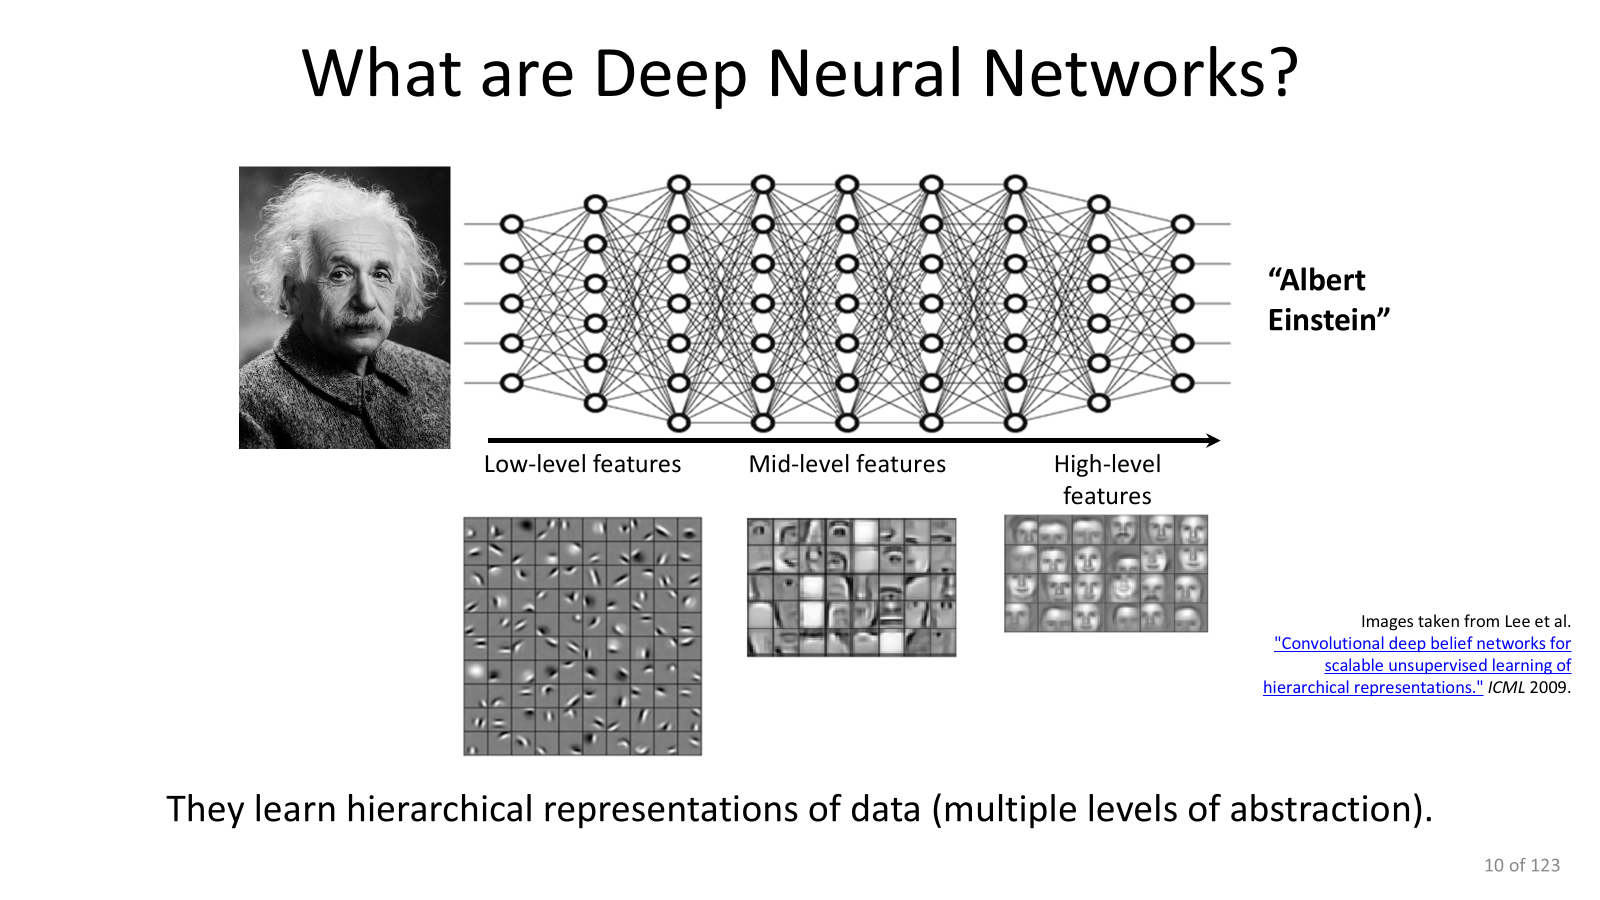


<font color='blue'>**Referencias:** [Zeiler y Fergus, Visualizing and Understanding Convolutional Networks (ECCV 2014)](https://arxiv.org/abs/1311.2901); [Yosinski et al., Understanding Neural Networks Through Deep Visualization (2015)](https://arxiv.org/abs/1506.06579); [Olah et al., Feature Visualization (Distill, 2017)](https://distill.pub/2017/feature-visualization/). **Material complementario:** [CS231n, Visualizing what ConvNets learn](https://cs231n.github.io/understanding-cnn/).</font>


In [ ]:
# A CUBRIR POR EL ALUMNADO